In [1]:
# Cell 1: Environment Setup, Disk Quota Management & Codebase Extraction
import os, sys, glob, shutil, base64, io, tarfile

# 1. Proactively manage Kaggle disk space:
# If cache was partially filled from a previous run and filled the 20GB disk quota,
# immediately prune down to 180 cases (~14.4GB) to free 6+ GB of disk space.
cache_dir = '/kaggle/working/cache'
if os.path.exists(cache_dir):
    imgs = sorted(glob.glob(os.path.join(cache_dir, '*_img.npy')))
    if len(imgs) > 180:
        print(f"Detected {len(imgs)} cases in cache. Pruning to 180 to immediately free 6+ GB of disk space...")
        keep = set(os.path.basename(p)[:-8] for p in imgs[:180])
        for f in glob.glob(os.path.join(cache_dir, '*')):
            if os.path.basename(f)[:-8] not in keep:
                try:
                    os.remove(f)
                except Exception:
                    pass
        print(f"Pruning complete! Retained {len(glob.glob(os.path.join(cache_dir, '*_img.npy')))} cases.")

# 2. Extract the latest cfseg codebase into /kaggle/working/cfseg
WORK_DIR = '/kaggle/working/cfseg'
os.makedirs(WORK_DIR, exist_ok=True)

B64_DATA = """..."""
tar_bytes = base64.b64decode(B64_DATA)
with tarfile.open(fileobj=io.BytesIO(tar_bytes), mode='r:gz') as tar:
    try:
        tar.extractall(path=WORK_DIR, filter='data')
    except TypeError:
        tar.extractall(path=WORK_DIR)
print('Latest cfseg codebase extracted successfully into', WORK_DIR)

# 3. Configure Git remote origin so future 'git pull' commands know exactly where to pull from
%cd /kaggle/working/cfseg
!git init -q
!git remote add origin https://github.com/pengeon1/idse-project.git 2>/dev/null || git remote set-url origin https://github.com/pengeon1/idse-project.git
!git fetch origin main -q 2>/dev/null && git reset --hard origin/main -q 2>/dev/null || true

# 4. Install dependencies
!pip install -q nibabel scipy matplotlib tabulate pandas

# 5. Run smoke test suite
!python -m pytest -p no:launch_testing tests/test_smoke.py -v


Latest cfseg codebase extracted successfully into /kaggle/working/cfseg
/kaggle/working/cfseg
============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /kaggle/working/cfseg
plugins: typeguard-4.6.0, anyio-4.14.2, langsmith-0.12.1
collected 7 items                                                              

tests/test_smoke.py::test_finenet_shapes PASSED                          [ 14%]
tests/test_smoke.py::test_coarsenet_shapes PASSED                        [ 28%]
tests/test_smoke.py::test_dice_boundary_loss PASSED                      [ 42%]
tests/test_smoke.py::test_modality_dropout PASSED                        [ 57%]
tests/test_smoke.py::test_crop_pad PASSED                                [ 71%]
tests/test_smoke.py::test_bbox_of PASSED                                 [ 85%]
tests/test_smoke.py::test_model_variants PASSED                        

In [2]:
# Cell 2: Run Master Training, Evaluation & Ablation Pipeline
%cd /kaggle/working/cfseg

# Master Runner automatically:
# - Auto-discovers raw BraTS dataset under /kaggle/input
# - Preprocesses up to 180 cases (skips if 180 cases already in cache)
# - Performs 3-case spot-check verification & generates montage
# - Trains Stage 1 CoarseNet (100 epochs, saves runs/s1/best.pt)
# - Trains Stage 2 FineNet A0 Full Model (150 epochs, saves runs/s2_a0_full/best.pt)
# - Evaluates full two-stage pipeline on held-out test split (Dice, HD95, latency, peak VRAM)
# - Generates 4-panel qualitative visual overlays (best, median, worst, S1 failure)
# - Runs all controlled ablations (A1 to A7) + missing modality tests
# - Compiles markdown comparison tables and creates /kaggle/working/results_bundle.zip

!python scripts/run_kaggle_pipeline.py --work_dir /kaggle/working --max_cases 180 --s1_epochs 100 --s2_epochs 150 --skip_ablations --batch_size 2


/kaggle/working/cfseg
Searching for raw BraTS dataset in: ['/kaggle/input', '/content', './data', '.']
Mounted folders in /kaggle/input:
  - /kaggle/input/datasets

[+] Found labeled BraTS dataset with ground-truth 'seg' masks at:
    /kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData

Valid labeled cases currently in cache: 0

>>> Step 1: Preprocessing raw BraTS NIfTI files to z-scored .npy cache (max 180 cases)
Executing: python data.py preprocess --raw '/kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData' --out '/kaggle/working/cache' --max_cases 180
done BraTS20_Training_001
done BraTS20_Training_002
done BraTS20_Training_003
done BraTS20_Training_004
done BraTS20_Training_005
done BraTS20_Training_006
done BraTS20_Training_007
done BraTS20_Training_008
done BraTS20_Training_009
done BraTS20_Training_010
done BraTS20_Training_011
done BraTS20_Trai

BRAIN TUMOR SEGMENTATION: ABLATION STUDY & EVALUATION RESULTS


# Ablation Study Results

|                                | WT_Dice      | TC_Dice      | ET_Dice      |   WT_HD95 | Time/case   | Max_Mem   |
|:-------------------------------|:-------------|:-------------|:-------------|----------:|:------------|:----------|
| A0 (Full)                      | 0.9127±0.065 | 0.8994±0.112 | 0.8488±0.088 |      2.76 | 0.39s       | 818MB     |
| A1 (Attention Gate skip)       | 0.9058±0.064 | 0.9145±0.059 | 0.8555±0.086 |      3.35 | 0.35s       | 818MB     |
| A2 (No skip attention)         | 0.8995±0.071 | 0.9067±0.067 | 0.8403±0.098 |      3.88 | 0.33s       | 761MB     |
| A3 (No Transformer bottleneck) | 0.9074±0.054 | 0.8896±0.114 | 0.8370±0.087 |      2.91 | 0.37s       | 812MB     |
| A4 (No dilated convolutions)   | 0.9077±0.054 | 0.8852±0.126 | 0.8284±0.091 |      2.85 | 0.37s       | 802MB     |
| A5 (No modality dropout)       | 0.9090±0.056 | 0.9103±0.063 | 0.8343±0.087 |      2.81 | 0.37s       | 818MB     |
| A6 (No boundary loss)          | 0.9069±0.056 | 0.8818±0.122 | 0.8349±0.083 |      3.16 | 0.38s       | 818MB     |
| A7 (Single-stage)              | 0.8086±0.189 | 0.8027±0.223 | 0.7715±0.195 |     26.22 | 0.73s       | 3123MB    |

## Missing Modality Robustness

| Model        | Dropped   |   WT_Dice |   TC_Dice |   ET_Dice |
|:-------------|:----------|----------:|----------:|----------:|
| A0_ModDrop   | t1,t2     |    0.9053 |    0.8879 |    0.8436 |
| A5_NoModDrop | t1,t2     |    0.8808 |    0.8761 |    0.7985 |
| A0_ModDrop   | flair     |    0.8525 |    0.8687 |    0.8307 |
| A5_NoModDrop | flair     |    0.6805 |    0.7136 |    0.7352 |
| A0_ModDrop   | t1ce      |    0.8977 |    0.685  |    0.467  |
| A5_NoModDrop | t1ce      |    0.8887 |    0.565  |    0.2753 |



--- Stage 2 (A0 Full Model) Loss & Validation Dice Trajectory ---


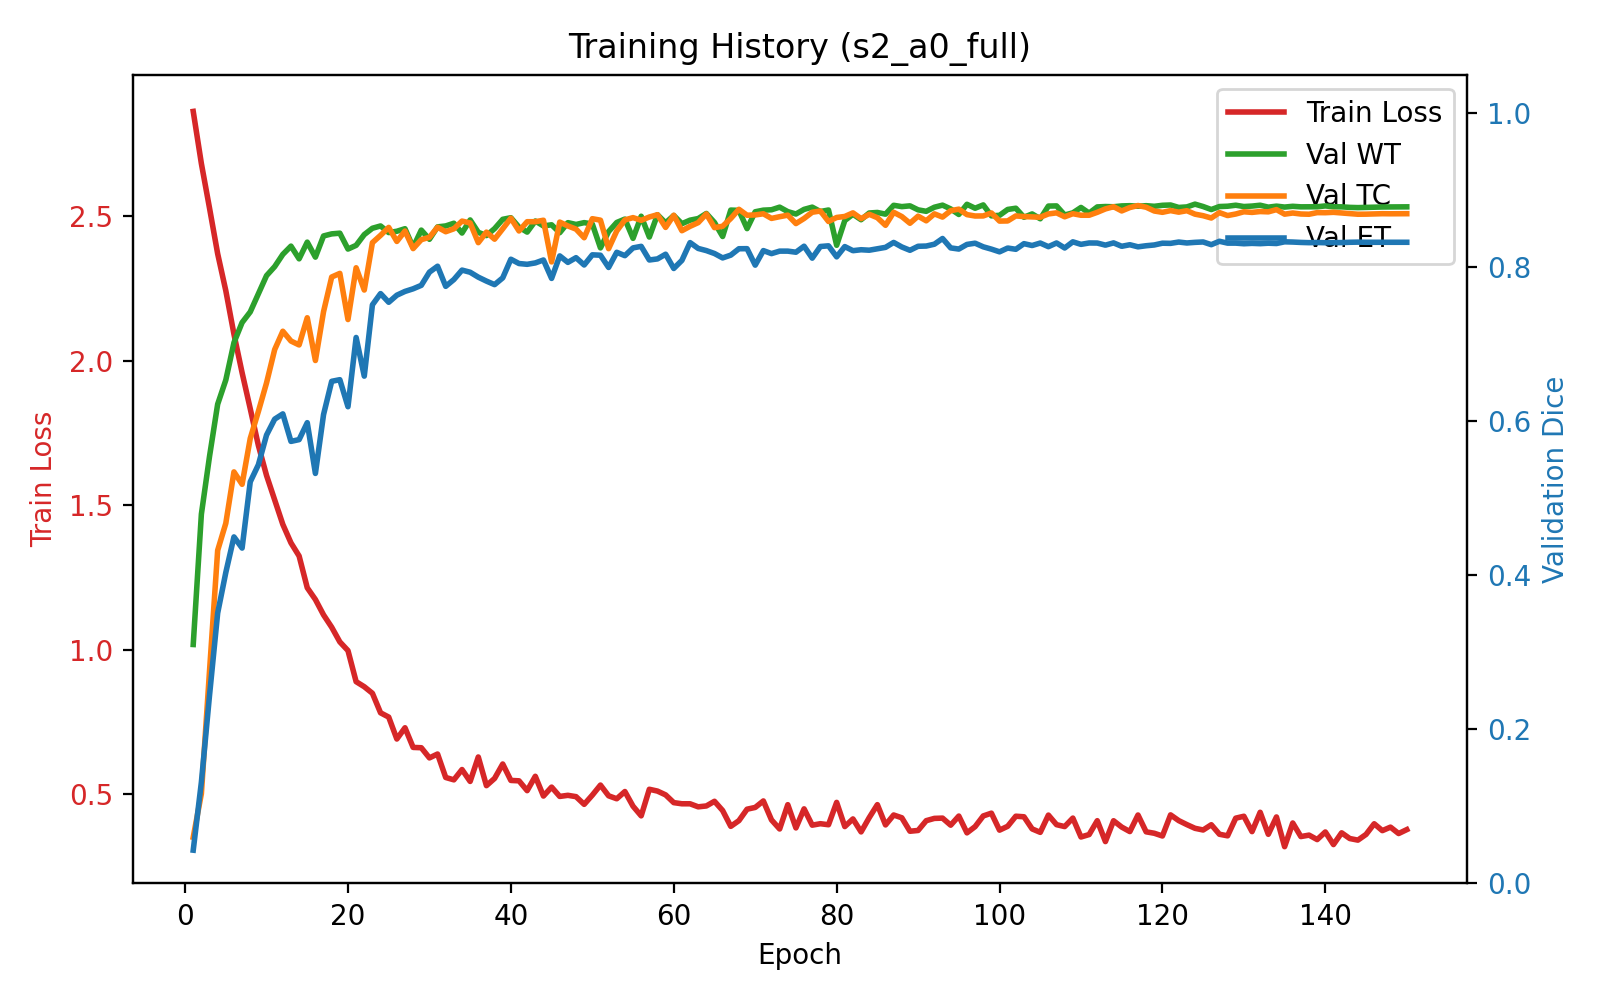


--- Qualitative Visual Overlays (4 cases) ---
Displaying: best_BraTS20_Training_098_slice92.png


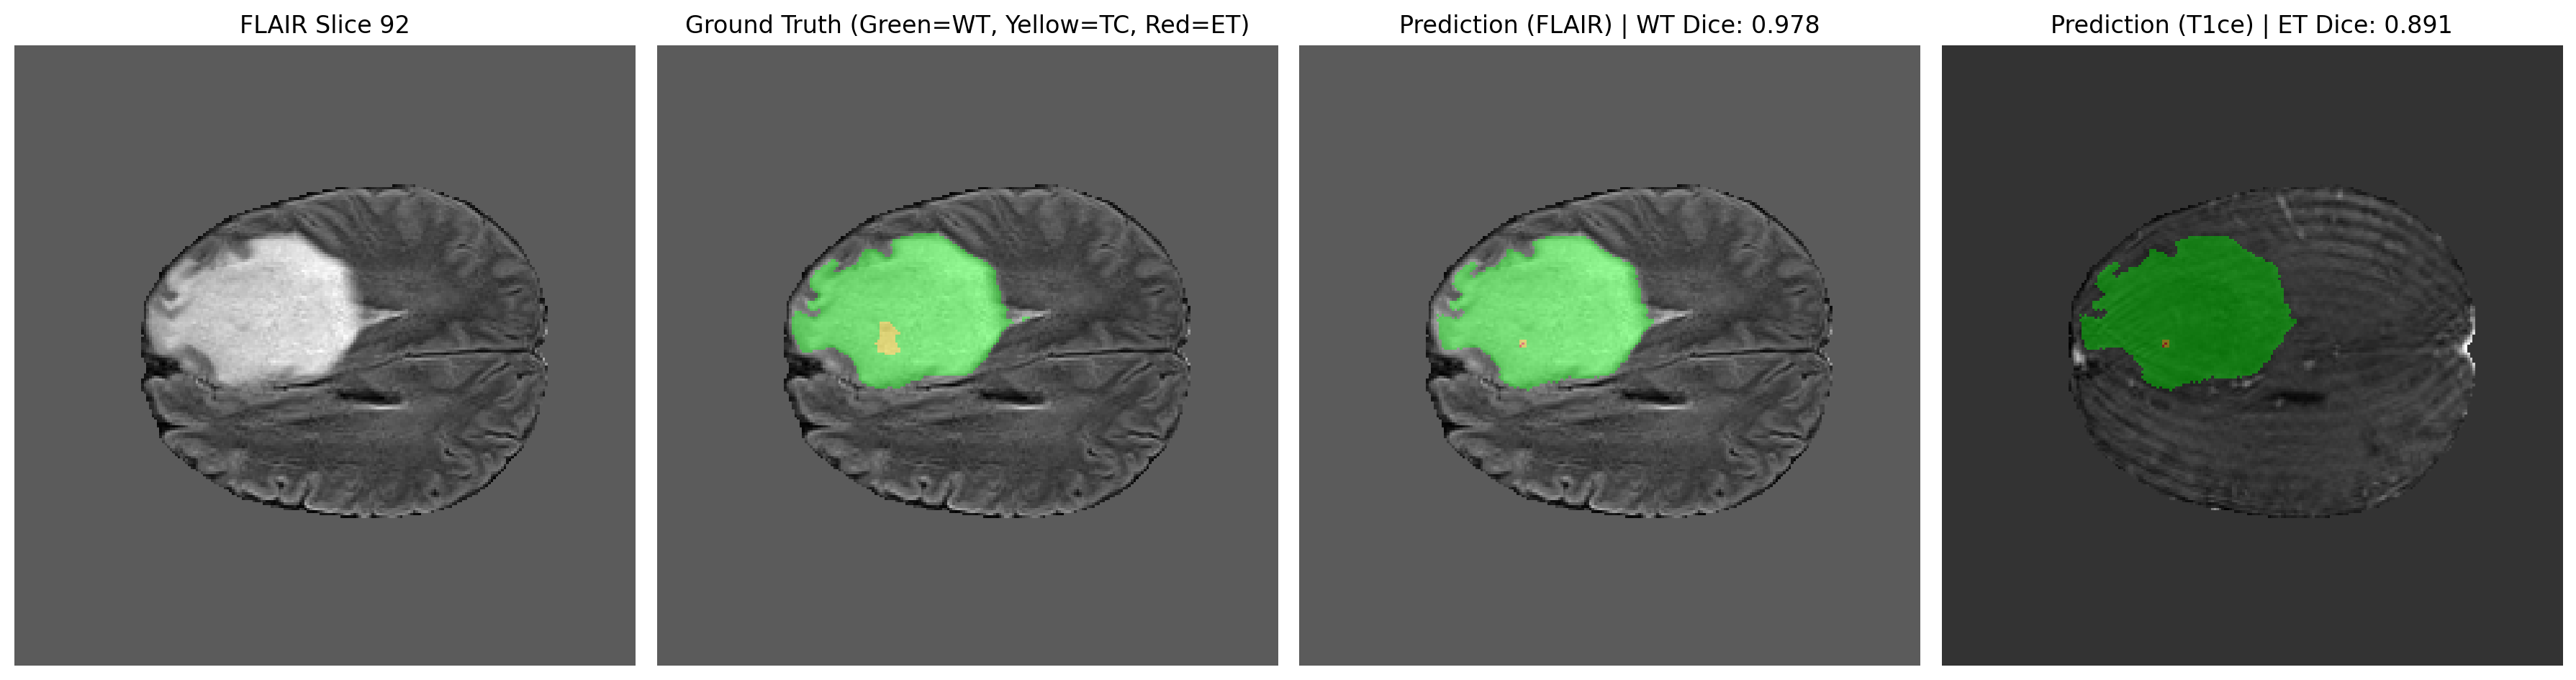

Displaying: median_BraTS20_Training_090_slice80.png


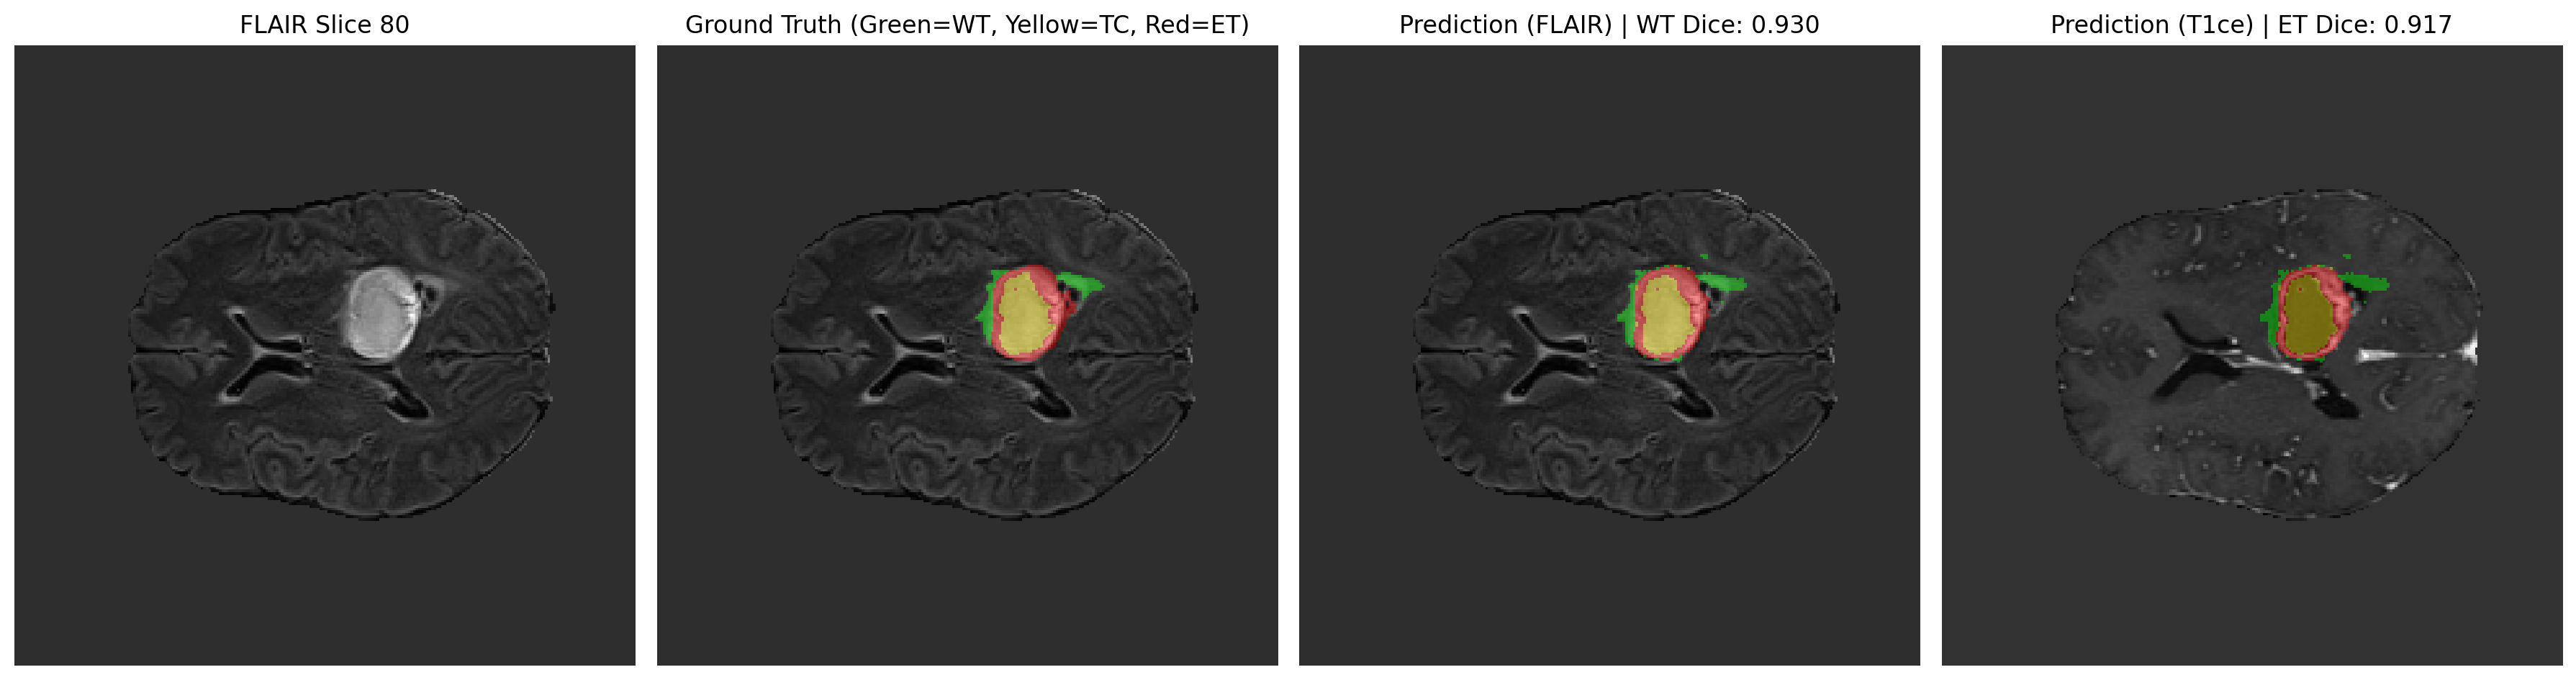

Displaying: s1_failure_BraTS20_Training_158_slice45.png


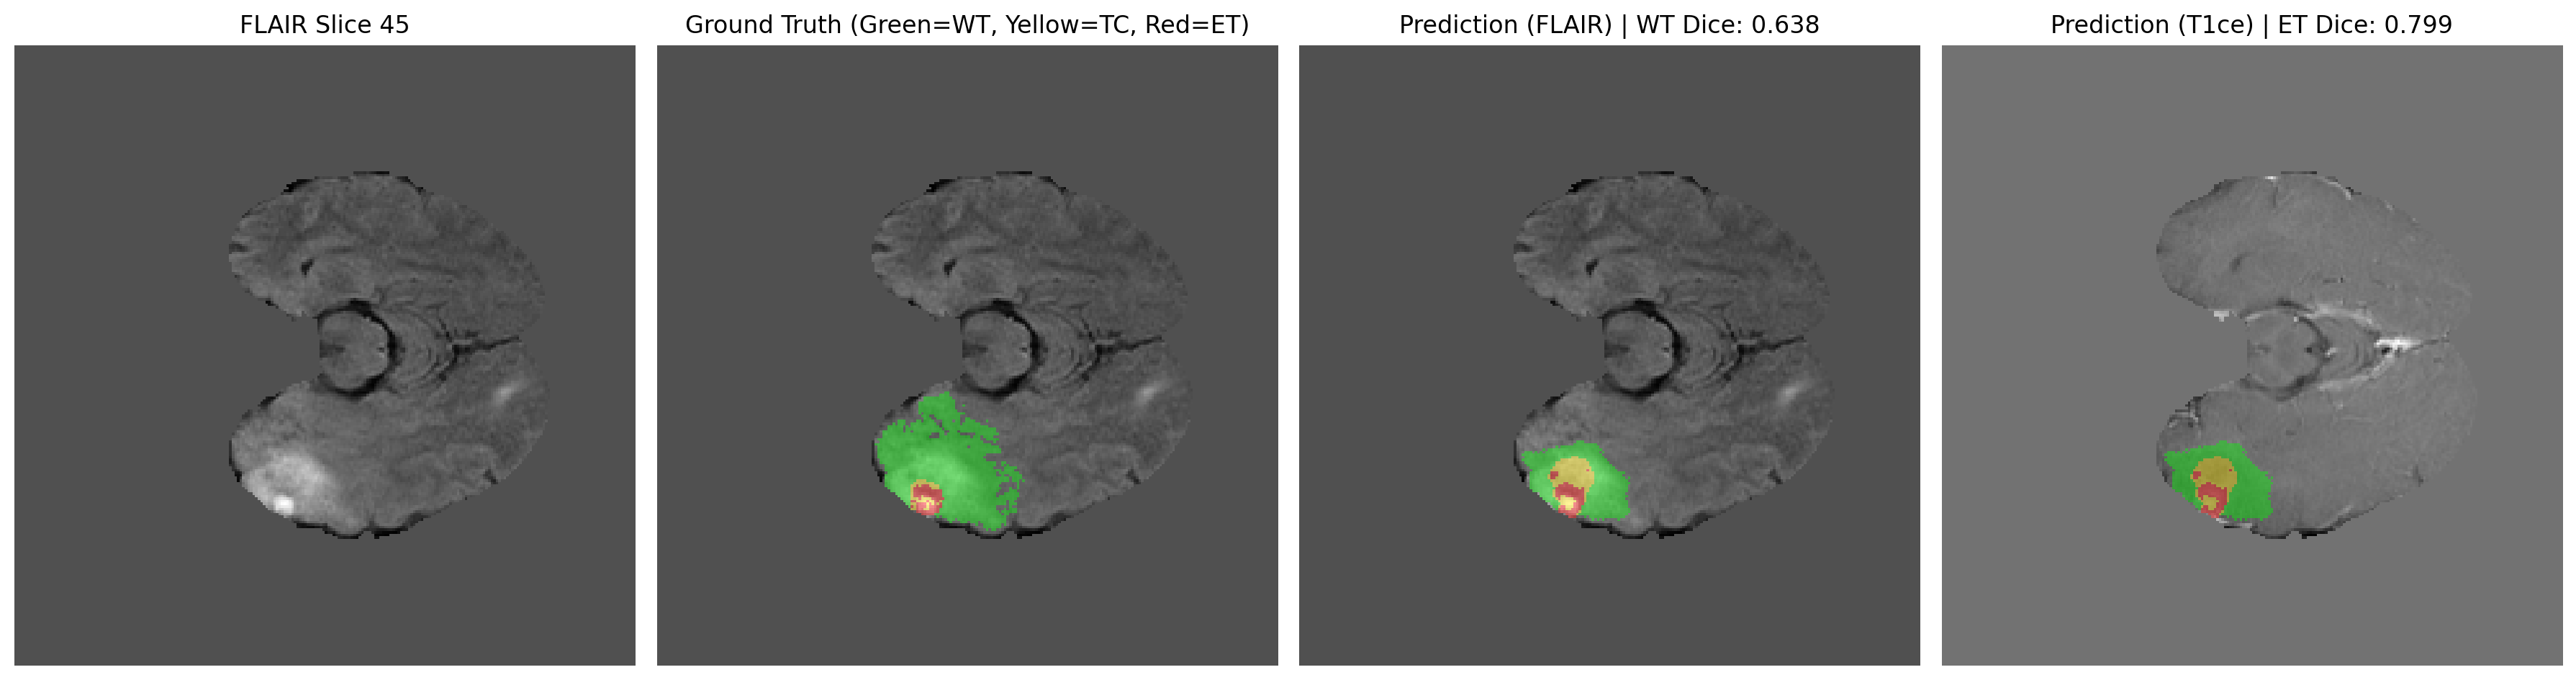

Displaying: worst_BraTS20_Training_158_slice45.png


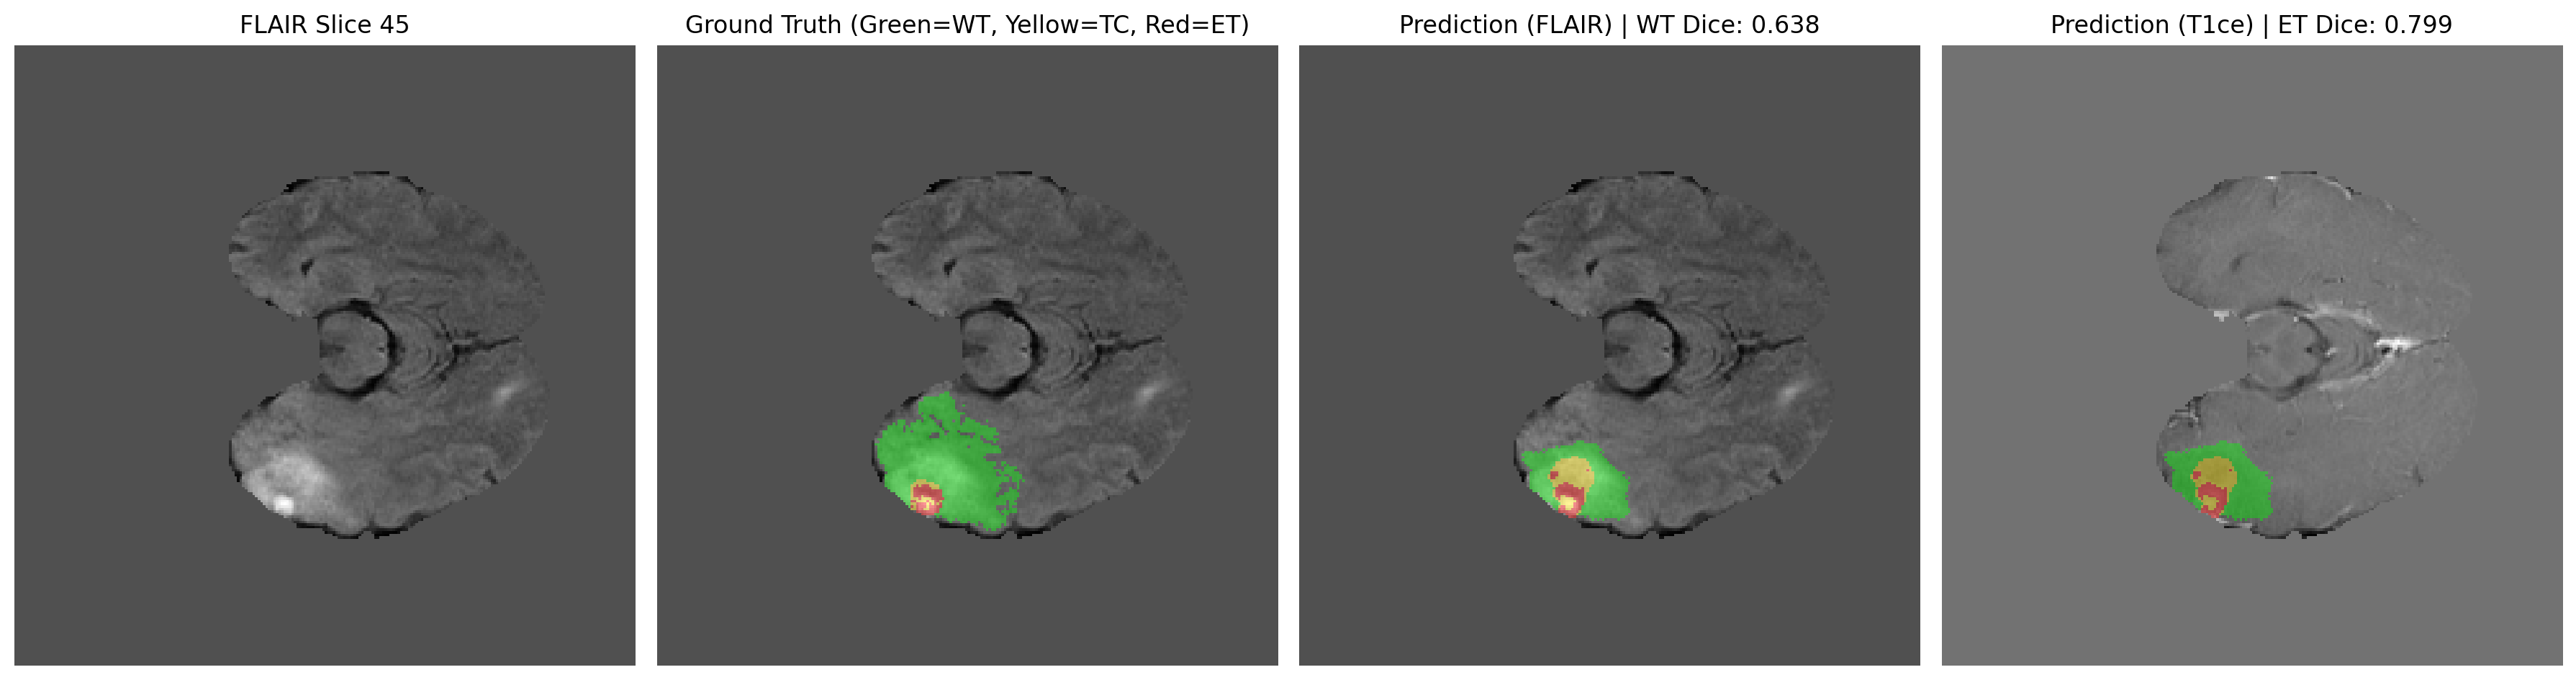


Results bundle ready for download:


/kaggle/working/results_bundle.zip

In [3]:
# Cell 3: View Results, Tables & Qualitative Overlays
import os, glob
import pandas as pd
from IPython.display import display, Markdown, Image, FileLink

print("=" * 80)
print("BRAIN TUMOR SEGMENTATION: ABLATION STUDY & EVALUATION RESULTS")
print("=" * 80)

# Display Ablation Summary Markdown Table
if os.path.exists('/kaggle/working/results/ABLATION_TABLE.md'):
    with open('/kaggle/working/results/ABLATION_TABLE.md') as f:
        display(Markdown(f.read()))

# Display Training Curves
if os.path.exists('/kaggle/working/results/curves_stage2_a0.png'):
    print("\n--- Stage 2 (A0 Full Model) Loss & Validation Dice Trajectory ---")
    display(Image('/kaggle/working/results/curves_stage2_a0.png'))

# Display Qualitative 4-Panel Overlays
overlays = sorted(glob.glob('/kaggle/working/results/overlays_a0/*.png'))
if overlays:
    print(f"\n--- Qualitative Visual Overlays ({len(overlays)} cases) ---")
    for p in overlays:
        print(f"Displaying: {os.path.basename(p)}")
        display(Image(p))

if os.path.exists('/kaggle/working/results_bundle.zip'):
    print("\nResults bundle ready for download:")
    display(FileLink('/kaggle/working/results_bundle.zip'))


In [4]:
# Cell 4: Run Advanced Improvements: A (Generalization), B (Adaptive Margin), C (TTA)
%cd /kaggle/working/cfseg
!git fetch origin main -q 2>/dev/null && git reset --hard origin/main -q 2>/dev/null || true

# Runs all advanced evaluations in ~3-5 minutes on GPU (zero retraining needed):
# - B: Uncertainty-Aware Adaptive Margin (fixes Stage 1 peripheral truncation)
# - C: 4-Fold Test-Time Augmentation (TTA spatial flip ensembling)
# - B + C: Combined peak accuracy pipeline
# - A: Scanner Domain Shifts (Gamma 0.75, Gamma 1.35, RF Bias Field, Gaussian Noise)
# - Cross-Dataset: Auto-detects and evaluates on BraTS 2021/2023 if attached in /kaggle/input
!python scripts/run_advanced_eval.py --work_dir /kaggle/working --split test

import os
from IPython.display import display, Markdown, FileLink

if os.path.exists("/kaggle/working/results/ADVANCED_RESULTS.md"):
    print("=" * 80)
    print("ADVANCED RESULTS (A, B, C) SUMMARY TABLE:")
    print("=" * 80)
    with open("/kaggle/working/results/ADVANCED_RESULTS.md") as f:
        display(Markdown(f.read()))

if os.path.exists("/kaggle/working/advanced_results_bundle.zip"):
    print("Download Advanced Results Bundle:")
    display(FileLink("/kaggle/working/advanced_results_bundle.zip"))


/kaggle/working/cfseg

RUNNING ADVANCED IMPROVEMENTS: A (Generalization), B (Adaptive Margin), C (TTA)

>>> 1. Baseline (A0 Full): Standard Two-Stage Pipeline (fixed margin 12, single-pass)
Executing: python infer.py --cache '/kaggle/working/cache' --s1 '/kaggle/working/runs/s1/best.pt' --s2 '/kaggle/working/runs/s2_a0_full/best.pt' --split test  --out_csv '/kaggle/working/results/eval_baseline.csv'
BraTS20_Training_083  WT: 0.938 (HD: 1.4)  TC: 0.953 (HD: 1.0)  ET: 0.872 (HD: 1.0)  S1_Rec: 0.984  BoxOK: True  (1.10s, 588.7MB)
BraTS20_Training_095  WT: 0.968 (HD: 1.0)  TC: 0.894 (HD: 2.2)  ET: 0.845 (HD: 1.4)  S1_Rec: 0.983  BoxOK: True  (0.51s, 695.1MB)
BraTS20_Training_176  WT: 0.961 (HD: 1.4)  TC: 0.648 (HD: 15.6)  ET: 0.528 (HD: 5.1)  S1_Rec: 0.973  BoxOK: True  (0.29s, 588.7MB)
BraTS20_Training_179  WT: 0.926 (HD: 2.2)  TC: 0.916 (HD: 2.4)  ET: 0.822 (HD: 2.4)  S1_Rec: 0.957  BoxOK: True  (0.31s, 456.7MB)
BraTS20_Training_166  WT: 0.925 (HD: 2.0)  TC: 0.967 (HD: 1.0)  ET: 0.923 (H

# Advanced Results: Generalization (A), Adaptive Margin (B), and TTA (C)

| Evaluation Scenario | WT_Dice | TC_Dice | ET_Dice | WT_HD95 | S1_Recall | Box_OK | Time/case | Peak_Mem |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **1. Baseline (A0 Full)** | 0.9083±0.069 | 0.9048±0.095 | 0.8526±0.083 | 2.93 | 94.8% | 20/27 | 0.39s | 829MB |
| **2. Adaptive Margin (B)** | 0.9101±0.067 | 0.9054±0.099 | 0.8541±0.084 | 2.81 | 94.8% | 21/27 | 0.52s | 829MB |
| **3. Test-Time Aug (C)** | 0.9115±0.068 | 0.9053±0.097 | 0.8565±0.083 | 2.92 | 94.8% | 20/27 | 0.59s | 883MB |
| **4. Combined Adaptive + TTA (B+C)** | 0.9127±0.068 | 0.9071±0.097 | 0.8579±0.083 | 2.85 | 94.8% | 21/27 | 0.73s | 883MB |
| **5. Scanner Shift: Gamma Low** | 0.9088±0.069 | 0.9053±0.095 | 0.8524±0.087 | 2.89 | 94.9% | 20/27 | 0.39s | 829MB |
| **6. Scanner Shift: Gamma High** | 0.9093±0.063 | 0.9032±0.100 | 0.8504±0.078 | 2.83 | 94.1% | 19/27 | 0.39s | 818MB |
| **7. Scanner Shift: Bias Field** | 0.9097±0.068 | 0.9027±0.099 | 0.8523±0.083 | 2.87 | 94.7% | 20/27 | 0.39s | 829MB |
| **8. Scanner Shift: Low SNR Noise** | 0.9066±0.070 | 0.9045±0.096 | 0.8519±0.083 | 2.96 | 94.8% | 20/27 | 0.39s | 829MB |


Download Advanced Results Bundle:


/kaggle/working/advanced_results_bundle.zip